Predict future averge price of Meat, Fish and Eggs monthly by using SARIMAX model and Linear Regression Model
* According to the result, the Linear Regression Model is better than SARIMAX model.

<span style="color:red">Is that really decreased the price of Meat, Fish and Eggs yearly? Why?</span>

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2009-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preperation for Prediction

In [12]:
DMFEM = data.copy()
DMFEM = DMFEM[DMFEM['category']=='meat, fish and eggs']
DMFEM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
72,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (beef),beef,NaN,KG,actual,Retail,MMK,2424.24,1.3619
73,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,2909.09,1.6343
74,1/15/2008,Shan (South),Taunggyi,Hsihseng,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429


In [13]:
DMFEM = DMFEM[['date', 'price']]
DMFEM['date'] = pd.to_datetime(DMFEM['date'])
mask = (DMFEM['date']>=obv_st_date) & (DMFEM['date']<=obv_end_date)
DMFEM = DMFEM.loc[mask]
DMFEM = DMFEM.set_index('date')
DMFEM.head()

,price
date,
2008-01-15,3636.36
2008-01-15,3636.36
2008-01-15,2424.24
2008-01-15,2909.09
2008-01-15,3636.36


In [14]:
DMFEM = DMFEM.resample('MS').mean()
DMFEM.head()

,price
date,
2008-01-01,3249.997500
2008-02-01,3356.057500
2008-03-01,3545.453333
2008-04-01,3676.765000
2008-05-01,3767.673333


In [15]:
price = DMFEM['price']
date = DMFEM.index

##### Normalization data

In [16]:
scaler = MinMaxScaler()

In [17]:
DMFEM_nor = scaler.fit_transform(DMFEM)
DMFEM_nor = pd.DataFrame(DMFEM_nor)
DMFEM_nor.head()

,0
0,0.791009
1,0.833827
2,0.910288
3,0.963299
4,1.000000


In [18]:
DMFEM_nor['date']=date
DMFEM_nor = DMFEM_nor.set_index('date')
DMFEM_nor.columns=['price']
DMFEM_nor.head()

,price
date,
2008-01-01,0.791009
2008-02-01,0.833827
2008-03-01,0.910288
2008-04-01,0.963299
2008-05-01,1.000000


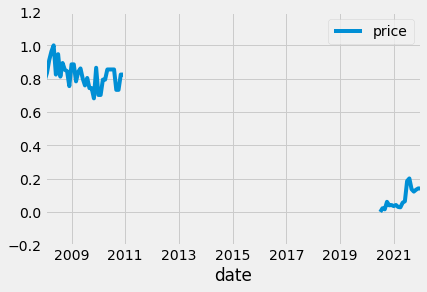

In [19]:
DMFEM_nor.plot(grid=True)
plt.show()

There is too many missing data. We need to fill

#####  Filling data with linear interpolation

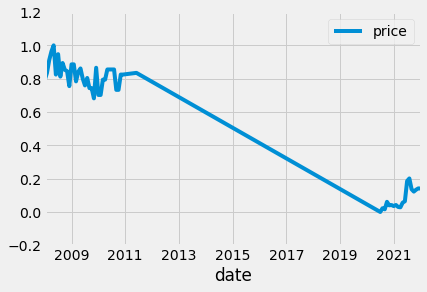

In [20]:
DMFEM_nor = DMFEM_nor.interpolate(method='linear')
DMFEM_nor.plot(grid=True)
plt.show()

There is negative trend.

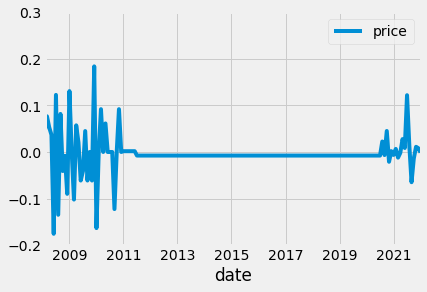

In [21]:
DMFEM_nor_diff1 = DMFEM_nor.diff(1).dropna()
DMFEM_nor_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [22]:
RW_DMFEM = adfuller(DMFEM_nor_diff1)
RW_DMFEM[1] # print P-value. If p-value<5%, reject null hypothesis

0.7730248226631093

<span style="color:red">What is influenced for this price?</span>

##### Plotting ACF and PACF

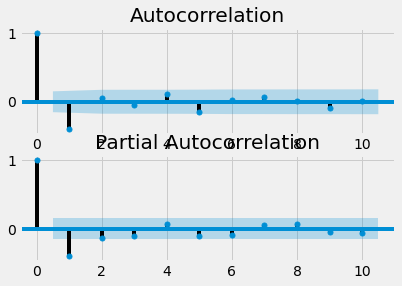

In [23]:
fig, axes=plt.subplots(2,1)
plot_acf(DMFEM_nor_diff1, lags=10, ax=axes[0])
plot_pacf(DMFEM_nor_diff1, lags=10, ax=axes[1])
plt.show()

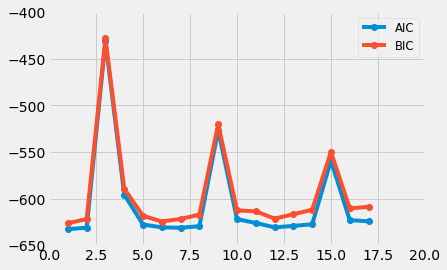

In [24]:
AIC, BIC = AIC_BIC_withOrderRange(DMFEM_nor_diff1,p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [25]:
AIC, BIC

(array([-605.78832899, -632.59562505, -631.21328263, -431.4734876 ,
        -595.65030073, -627.78029192, -630.74858531, -631.17220664,
        -629.54235286, -526.58689242, -621.96607598, -626.05951924,
        -630.78540063, -629.18051805, -627.51733543, -559.25570737,
        -623.00358854, -624.30590862]),
 array([-602.66436501, -626.34769709, -621.84139069, -428.35549378,
        -589.4143131 , -618.42631049, -624.50065735, -621.80031471,
        -617.04649694, -520.3509048 , -612.61209455, -613.58754399,
        -621.41350869, -616.68466214, -611.89751553, -549.90172593,
        -610.53161329, -608.71593956]))

We will run again 1:(0,0,1), 2:(0,0,2), 5:(0,1,2), 7:(1,0,1), 8:(1,0,2), 14:(2,0,2), 16:(2,1,1), 17:(2,1,2)

In [26]:
mod_orders = [
    (0,0,1), #0
    (0,0,2), #1
    (1,0,1), #2
    (1,0,2), #3
    (2,0,2), #4
]
mod_diff_orders = [
    (0,1,2), #5
    (2,1,1), #6
    (2,1,2), #7
]

In [27]:
DMFEM_models = []

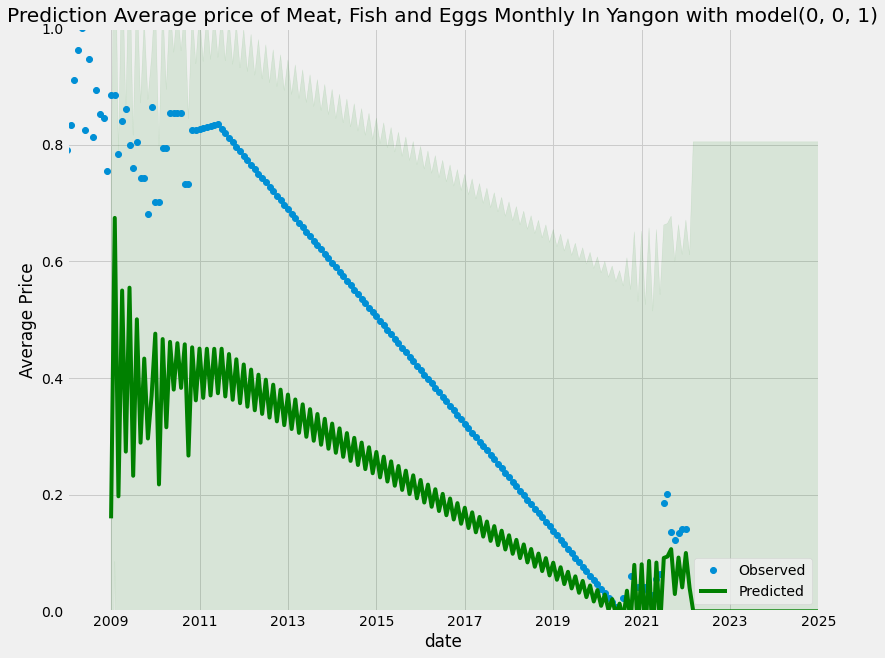

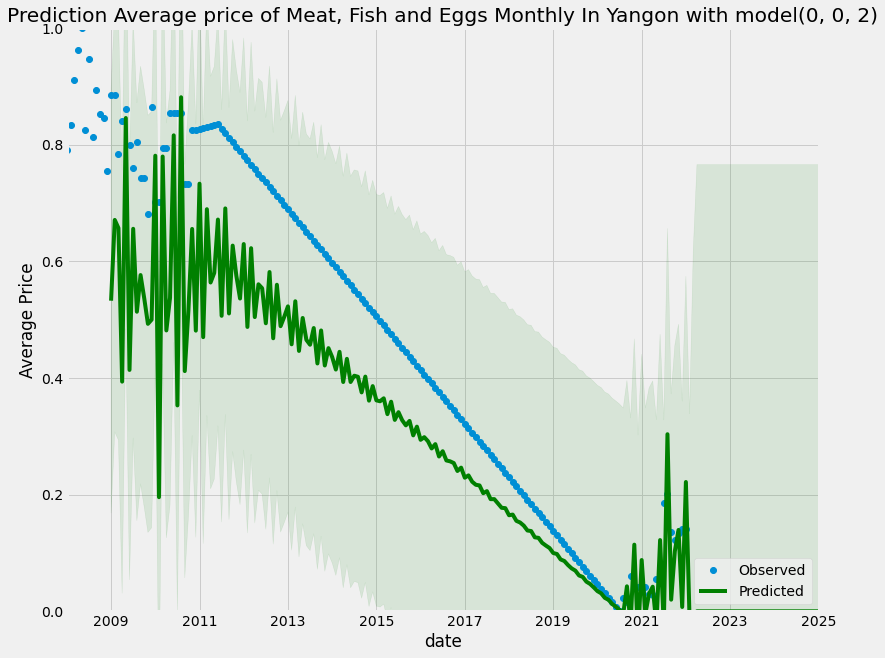

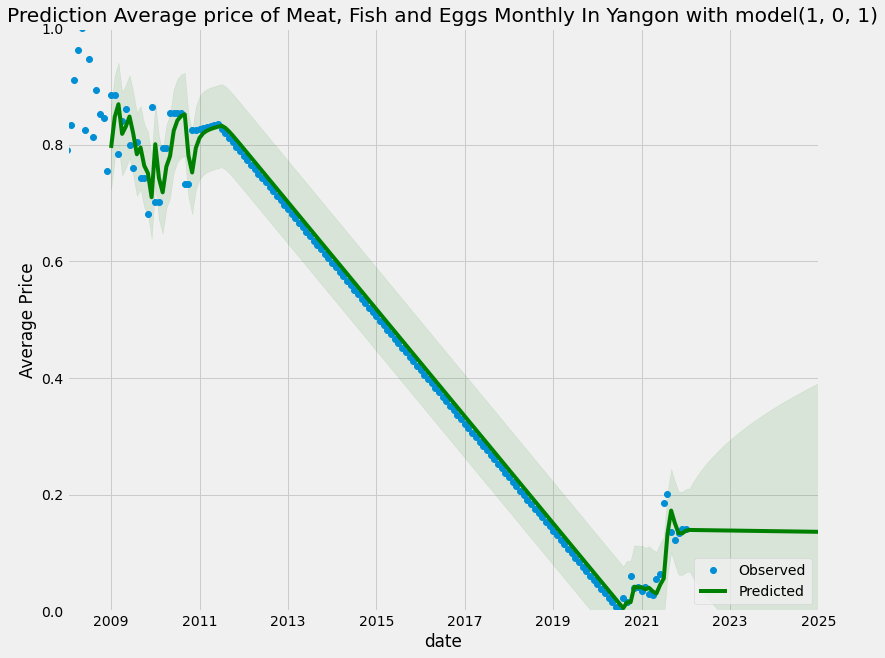

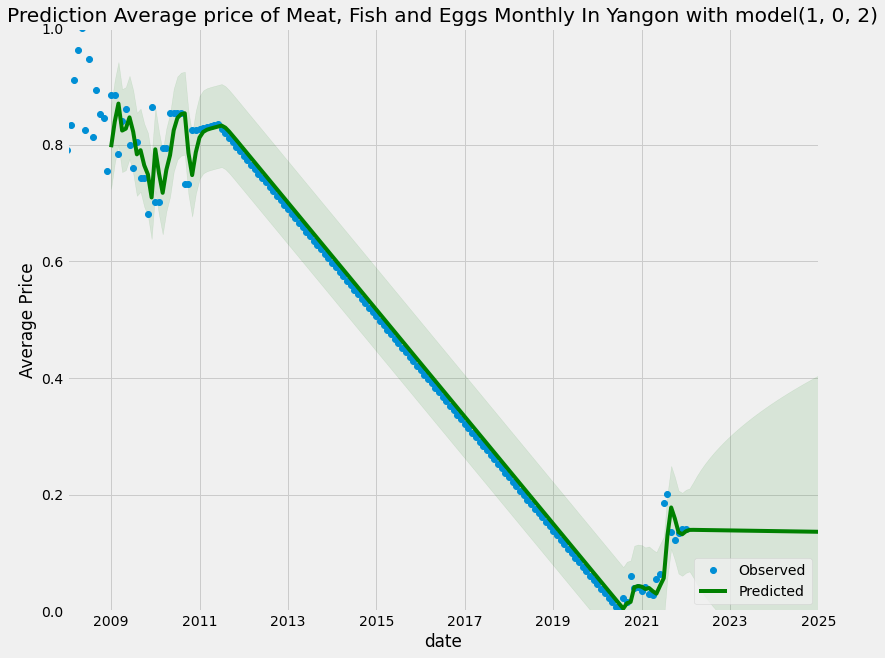

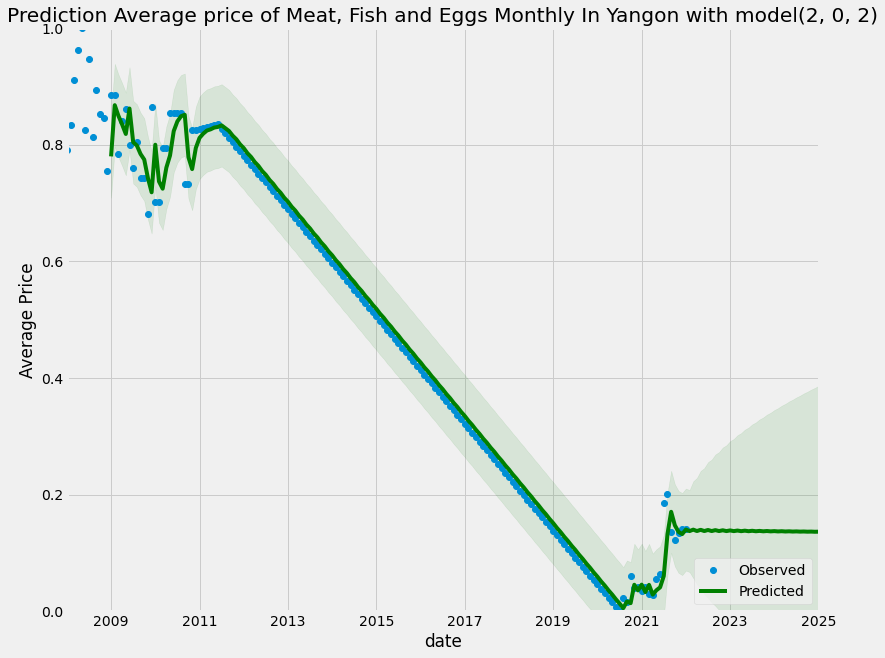

In [28]:
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DMFEM_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Meat, Fish and Eggs Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFEM_models.append(model)

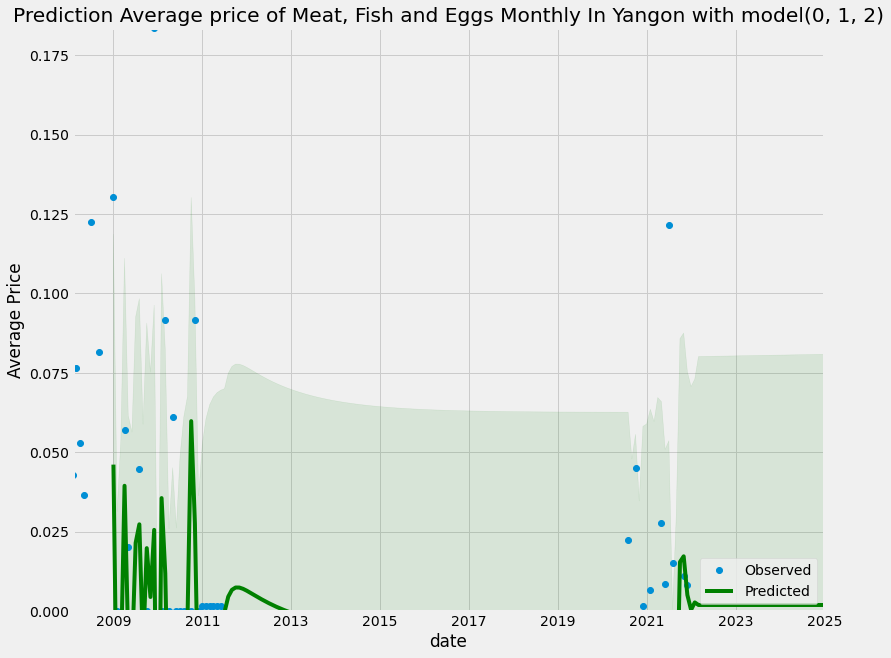

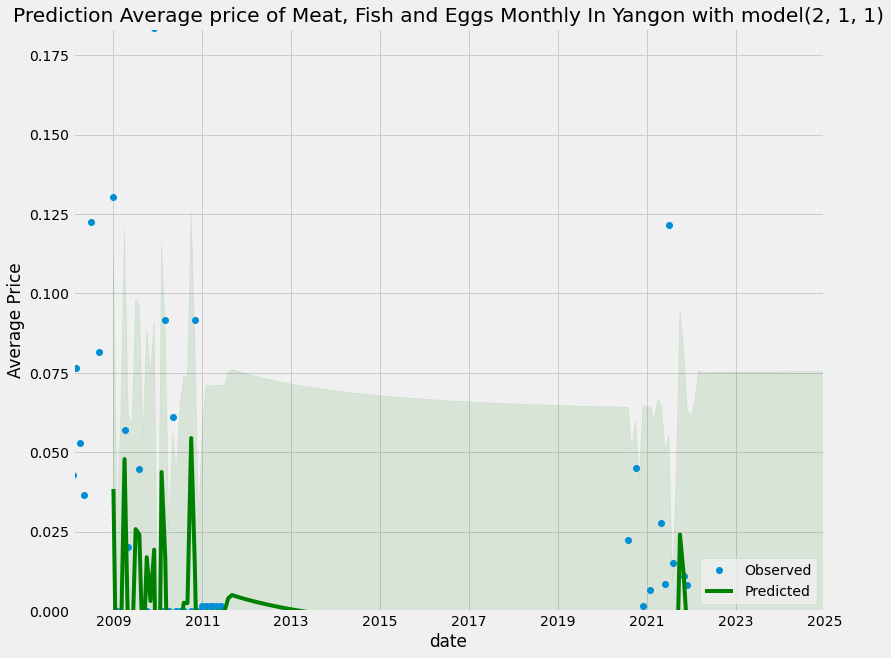

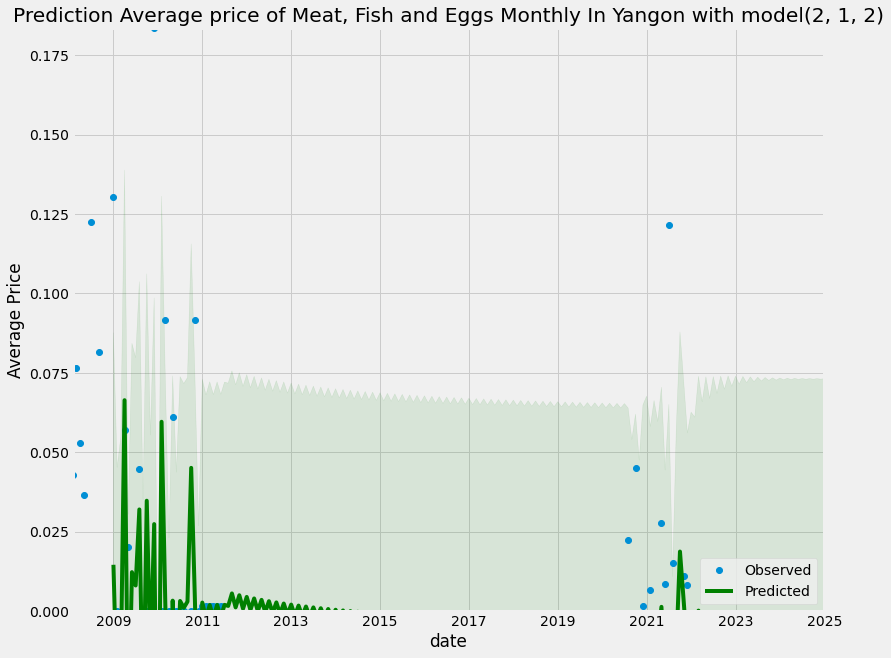

In [29]:
for ind, order in enumerate(mod_diff_orders): 
    model = Run_SARIMAX(DMFEM_nor_diff1, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Meat, Fish and Eggs Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFEM_models.append(model)

Now we choose (0,1,2)

In [30]:
DMFEM_model = DMFEM_models[5]

In [31]:
DMFEM_pred_normalized_diff1 = DMFEM_model.predict(pred_st_date, pred_end_date)
DMFEM_pred_normalized_diff1

2009-01-01    0.046154
2009-02-01   -0.040720
2009-03-01   -0.017921
2009-04-01    0.039494
2009-05-01   -0.009758
                ...   
2024-09-01    0.001986
2024-10-01    0.001986
2024-11-01    0.001986
2024-12-01    0.001986
2025-01-01    0.001986
Freq: MS, Length: 193, dtype: float64

In [32]:
DMFEM_pred_normalized_diff1_cumsum = DMFEM_pred_normalized_diff1.cumsum()
DMFEM_pred_normalized_diff1_cumsum

2009-01-01    0.046154
2009-02-01    0.005433
2009-03-01   -0.012488
2009-04-01    0.027007
2009-05-01    0.017248
                ...   
2024-09-01   -0.749373
2024-10-01   -0.747386
2024-11-01   -0.745400
2024-12-01   -0.743414
2025-01-01   -0.741427
Freq: MS, Length: 193, dtype: float64

In [33]:
mask = (DMFEM_nor.index>= pred_st_date) & (DMFEM_nor.index<= pred_end_date)
DMFEM_nor_pred = DMFEM_nor.loc[mask]
DMFEM_nor_pred

,price
date,
2009-01-01,0.885820
2009-02-01,0.885820
2009-03-01,0.783873
2009-04-01,0.840963
2009-05-01,0.861353
...,...
2021-09-01,0.136409
2021-10-01,0.122347
2021-11-01,0.133449


In [34]:
DMFEM_pred_normalized = pd.Series(DMFEM_nor_pred.iloc[0], index=DMFEM_nor_pred.index)
DMFEM_pred_normalized = DMFEM_pred_normalized.add(DMFEM_pred_normalized_diff1_cumsum,fill_value=0.84)
DMFEM_pred_normalized

2009-01-01    0.886154
2009-02-01    0.845433
2009-03-01    0.827512
2009-04-01    0.867007
2009-05-01    0.857248
                ...   
2024-09-01    0.090627
2024-10-01    0.092614
2024-11-01    0.094600
2024-12-01    0.096586
2025-01-01    0.098573
Length: 193, dtype: float64

We need to un-normalized the predicted value to get actual price

In [35]:
pred_date = DMFEM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2009-01-01', '2009-02-01', '2009-03-01', '2009-04-01',
               '2009-05-01', '2009-06-01', '2009-07-01', '2009-08-01',
               '2009-09-01', '2009-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=192, freq=None)

In [36]:
DMFEM_pred_normalized_df = pd.DataFrame(DMFEM_pred_normalized)
DMFEM_pred_normalized_df = DMFEM_pred_normalized_df[:-1] # the last index doesn't need
DMFEM_pred_normalized_df

,0
2009-01-01,0.886154
2009-02-01,0.845433
2009-03-01,0.827512
2009-04-01,0.867007
2009-05-01,0.857248
...,...
2024-08-01,0.088641
2024-09-01,0.090627
2024-10-01,0.092614
2024-11-01,0.094600


##### Un-normalization

In [37]:
DMFEM_pred_act = scaler.inverse_transform(DMFEM_pred_normalized_df)
DMFEM_pred_act_df = pd.DataFrame(DMFEM_pred_act)
DMFEM_pred_act_df['date'] = pred_date
DMFEM_pred_act_df.columns = ['Predicted Price', 'date']
DMFEM_pred_act_df.head()

,Predicted Price,date
0,3485.672579,2009-01-01
1,3384.806909,2009-02-01
2,3340.416415,2009-03-01
3,3438.244916,2009-04-01
4,3414.073145,2009-05-01


In [38]:
DMFEM_pred_act_df.set_index('date',  inplace=True)

In [39]:
DMFEM_pred_act_df['2020-09-01':'2022-09-01']

,Predicted Price
date,
2020-09-01,1864.160413
2020-10-01,1828.108947
2020-11-01,1740.111525
2020-12-01,1710.254735
2021-01-01,1682.208609
2021-02-01,1665.659282
2021-03-01,1639.503128
2021-04-01,1632.096723
2021-05-01,1621.437567


In [40]:
mask = (DMFEM.index>=pred_st_date) & (DMFEM.index<=pred_end_date)
DMFEM_Act = DMFEM.loc[mask]
DMFEM_Act

,price
date,
2009-01-01,3484.845000
2009-02-01,3484.845000
2009-03-01,3232.320000
2009-04-01,3373.735000
2009-05-01,3424.240000
...,...
2021-09-01,1628.534337
2021-10-01,1593.701149
2021-11-01,1621.202619


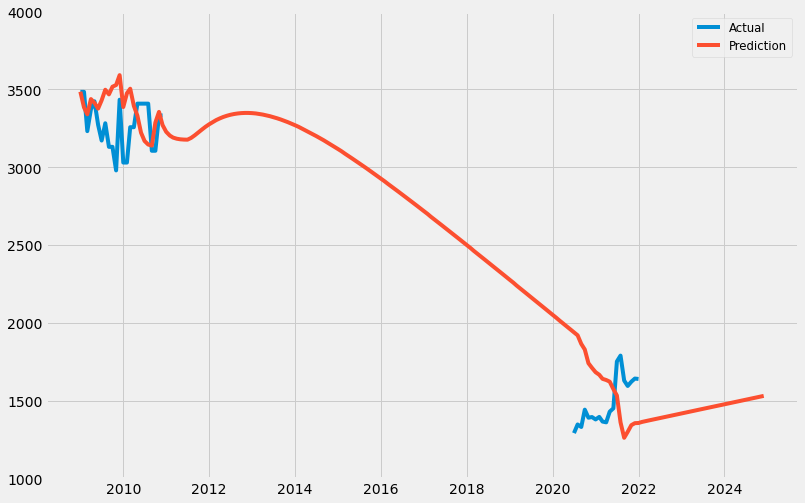

In [41]:
plt.figure(figsize=(12,8))
plt.plot(DMFEM_Act, label="Actual")
plt.plot(DMFEM_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [65]:
temp_df = DMFEM_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.791009
1,2008-02-01,0.833827
2,2008-03-01,0.910288
3,2008-04-01,0.963299
4,2008-05-01,1.000000
...,...,...
164,2021-09-01,0.136409
165,2021-10-01,0.122347
166,2021-11-01,0.133449
167,2021-12-01,0.141599


In [36]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 1   2008-08-01  0.857898  1217548800000000000
 2   2008-09-01  0.944021  1220227200000000000
 3   2008-10-01  0.900959  1222819200000000000
 4   2008-11-01  0.892346  1225497600000000000
 5   2008-12-01  0.797611  1228089600000000000
 ..         ...       ...                  ...
 158 2021-09-01  0.144045  1630454400000000000
 159 2021-10-01  0.129196  1633046400000000000
 160 2021-11-01  0.140920  1635724800000000000
 161 2021-12-01  0.149525  1638316800000000000
 162 2022-01-01  0.148365  1640995200000000000
 
 [132 rows x 3 columns],
           date     price                 time
 0   2008-07-01  1.000000  1214870400000000000
 15  2009-10-01  0.784693  1254355200000000000
 16  2009-11-01  0.720100  1257033600000000000
 21  2010-04-01  0.838519  1270080000000000000
 22  2010-05-01  0.903112  1272672000000000000
 27  2010-10-01  0.773927  1285891200000000000
 39  2011-10-01  0.849217  1317427200000000000
 41  2011-12-01  0.833042  132269

In [37]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1217548800000000000],
        [1220227200000000000],
        [1222819200000000000],
        [1225497600000000000],
        [1228089600000000000],
        [1230768000000000000],
        [1233446400000000000],
        [1235865600000000000],
        [1238544000000000000],
        [1241136000000000000]], dtype=int64),
 array([0.85789765, 0.94402063, 0.90095914, 0.89234627, 0.79761113,
        0.93540776, 0.93540776, 0.82775403, 0.88804055, 0.90957129]))

In [38]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1214870400000000000],
        [1254355200000000000],
        [1257033600000000000],
        [1270080000000000000],
        [1272672000000000000],
        [1285891200000000000],
        [1317427200000000000],
        [1322697600000000000],
        [1349049600000000000],
        [1372636800000000000]], dtype=int64),
 array([1.        , 0.78469254, 0.7201003 , 0.83851941, 0.90311164,
        0.77392717, 0.84921741, 0.83304184, 0.75216399, 0.67937393]))

In [39]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [40]:
DMFEM_linreg = LinearRegression().fit(X_train, y_train)

In [41]:
print('linear model coeff or slope (w): {}'.format(DMFEM_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DMFEM_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DMFEM_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DMFEM_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [-2.40084919e-18]
linear model intercept (b): 3.923
R-squared score (training): 0.945
R-squared score (test): 0.953


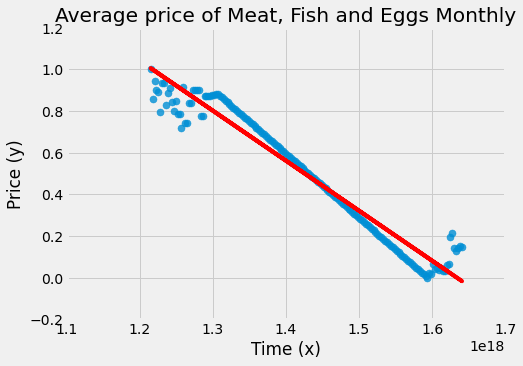

In [42]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DMFEM_linreg.coef_ * X + DMFEM_linreg.intercept_, 'r-')
plt.title('Average price of Meat, Fish and Eggs Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [43]:
DMFEM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DMFEM_linear_predict['time'] = DMFEM_linear_predict['date'].apply(lambda x: x.value)
DMFEM_linear_predict

,date,time
0,2015-07-01,1435708800000000000
1,2015-08-01,1438387200000000000
2,2015-09-01,1441065600000000000
3,2015-10-01,1443657600000000000
4,2015-11-01,1446336000000000000
...,...,...
110,2024-09-01,1725148800000000000
111,2024-10-01,1727740800000000000
112,2024-11-01,1730419200000000000
113,2024-12-01,1733011200000000000


In [44]:
time_predict = np.array(DMFEM_linear_predict['time']).reshape((-1, 1))
DMFEM_linear_predict['price'] = DMFEM_linreg.predict(time_predict)
DMFEM_linear_predict

,date,time,price
0,2015-07-01,1435708800000000000,0.475780
1,2015-08-01,1438387200000000000,0.469349
2,2015-09-01,1441065600000000000,0.462919
3,2015-10-01,1443657600000000000,0.456696
4,2015-11-01,1446336000000000000,0.450265
...,...,...,...
110,2024-09-01,1725148800000000000,-0.219122
111,2024-10-01,1727740800000000000,-0.225345
112,2024-11-01,1730419200000000000,-0.231776
113,2024-12-01,1733011200000000000,-0.237999


In [45]:
DMFEM_linear_normalized_predict = DMFEM_linear_predict.copy()
DMFEM_linear_normalized_predict = DMFEM_linear_normalized_predict[['date', 'price']]
DMFEM_linear_normalized_predict.set_index('date', inplace=True)
DMFEM_linear_normalized_predict

,price
date,
2015-07-01,0.475780
2015-08-01,0.469349
2015-09-01,0.462919
2015-10-01,0.456696
2015-11-01,0.450265
...,...
2024-09-01,-0.219122
2024-10-01,-0.225345
2024-11-01,-0.231776


##### Unnormalized the data

In [46]:
DMFEM_pred_act_linear = scaler.inverse_transform(DMFEM_linear_normalized_predict)
DMFEM_pred_act_linear_df = pd.DataFrame(DMFEM_pred_act_linear)
DMFEM_pred_act_linear_df['date'] = DMFEM_linear_predict['date']
DMFEM_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DMFEM_pred_act_linear_df.set_index('date', inplace=True)
DMFEM_pred_act_linear_df

,Predicted Price (KG)
date,
2015-07-01,2406.688367
2015-08-01,2391.604399
2015-09-01,2376.520430
2015-10-01,2361.923041
2015-11-01,2346.839073
...,...
2024-09-01,776.646612
2024-10-01,762.049223
2024-11-01,746.965255
